# TU Dublin Data Acquisition Project

## Pokemon Matchups and Stats Previwer

### Explanation

This project combines the following [kaggle dataset](https://www.kaggle.com/datasets/lmno3418/pokedex-pokemon-data) (final_combats.csv) with scrapped data from [pokemondb](https://pokemondb.net/).

The Kaggle dataset contains the matchup data that tells us which pokemons lose or win against a certain pokemon in equal conditions.

We combine this information with the stats from pokedex and we are able to tell which pokemon might work better for us in a playthrough.

### Data being displayed

A **good matchup** means the pokemon should **win** against another pokemon in equal conditions. A bad matchup means the oposite.

Pokemon Stats are certain parameters a pokemon has, it determines how strong a pokemon is. Doesn't mean the pokemon with most stats will always win, as it's overcomplicated how battles actually work.

**Stats:** HP (Hitpoints), Attack, Defence, Special Attack, Special Defence, Speed

## Installation

Below install the required pip libraries to run the project.

In [ ]:
!pip install pandas
!pip install beautifulsoup4
!pip install seaborn
!pip install numpy

import urllib.request
import http.client
from bs4 import BeautifulSoup
import pandas as pd
import json
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import time

## Configuration

Down below you are able to change which Generations does the script read from.

Chose a number from 1 to 8, it can use a range as well, so multiple generations.
Make sure `config_min_gen` and `config_max_gen` are either the same value or `config_min_gen` is smaller than `config_max_gen`

In [ ]:
config_min_gen = 1 # 1-8
config_max_gen = 1 # 1-8

config_combat_csv = "final_combats.csv"
config_stats_url = "https://pokemondb.net/pokedex/stats/gen"
sns.set_theme(style="darkgrid")

## The program

After the program finishes running, the plots should display downbelow. Keep in mind the program has been designed for the desktop version in mind (mathplot allows to zoom and move around the plots) as each generation has around 150 pokemon it might feel compact. For the best experience, open the imagines in a new tab.

Gen 1


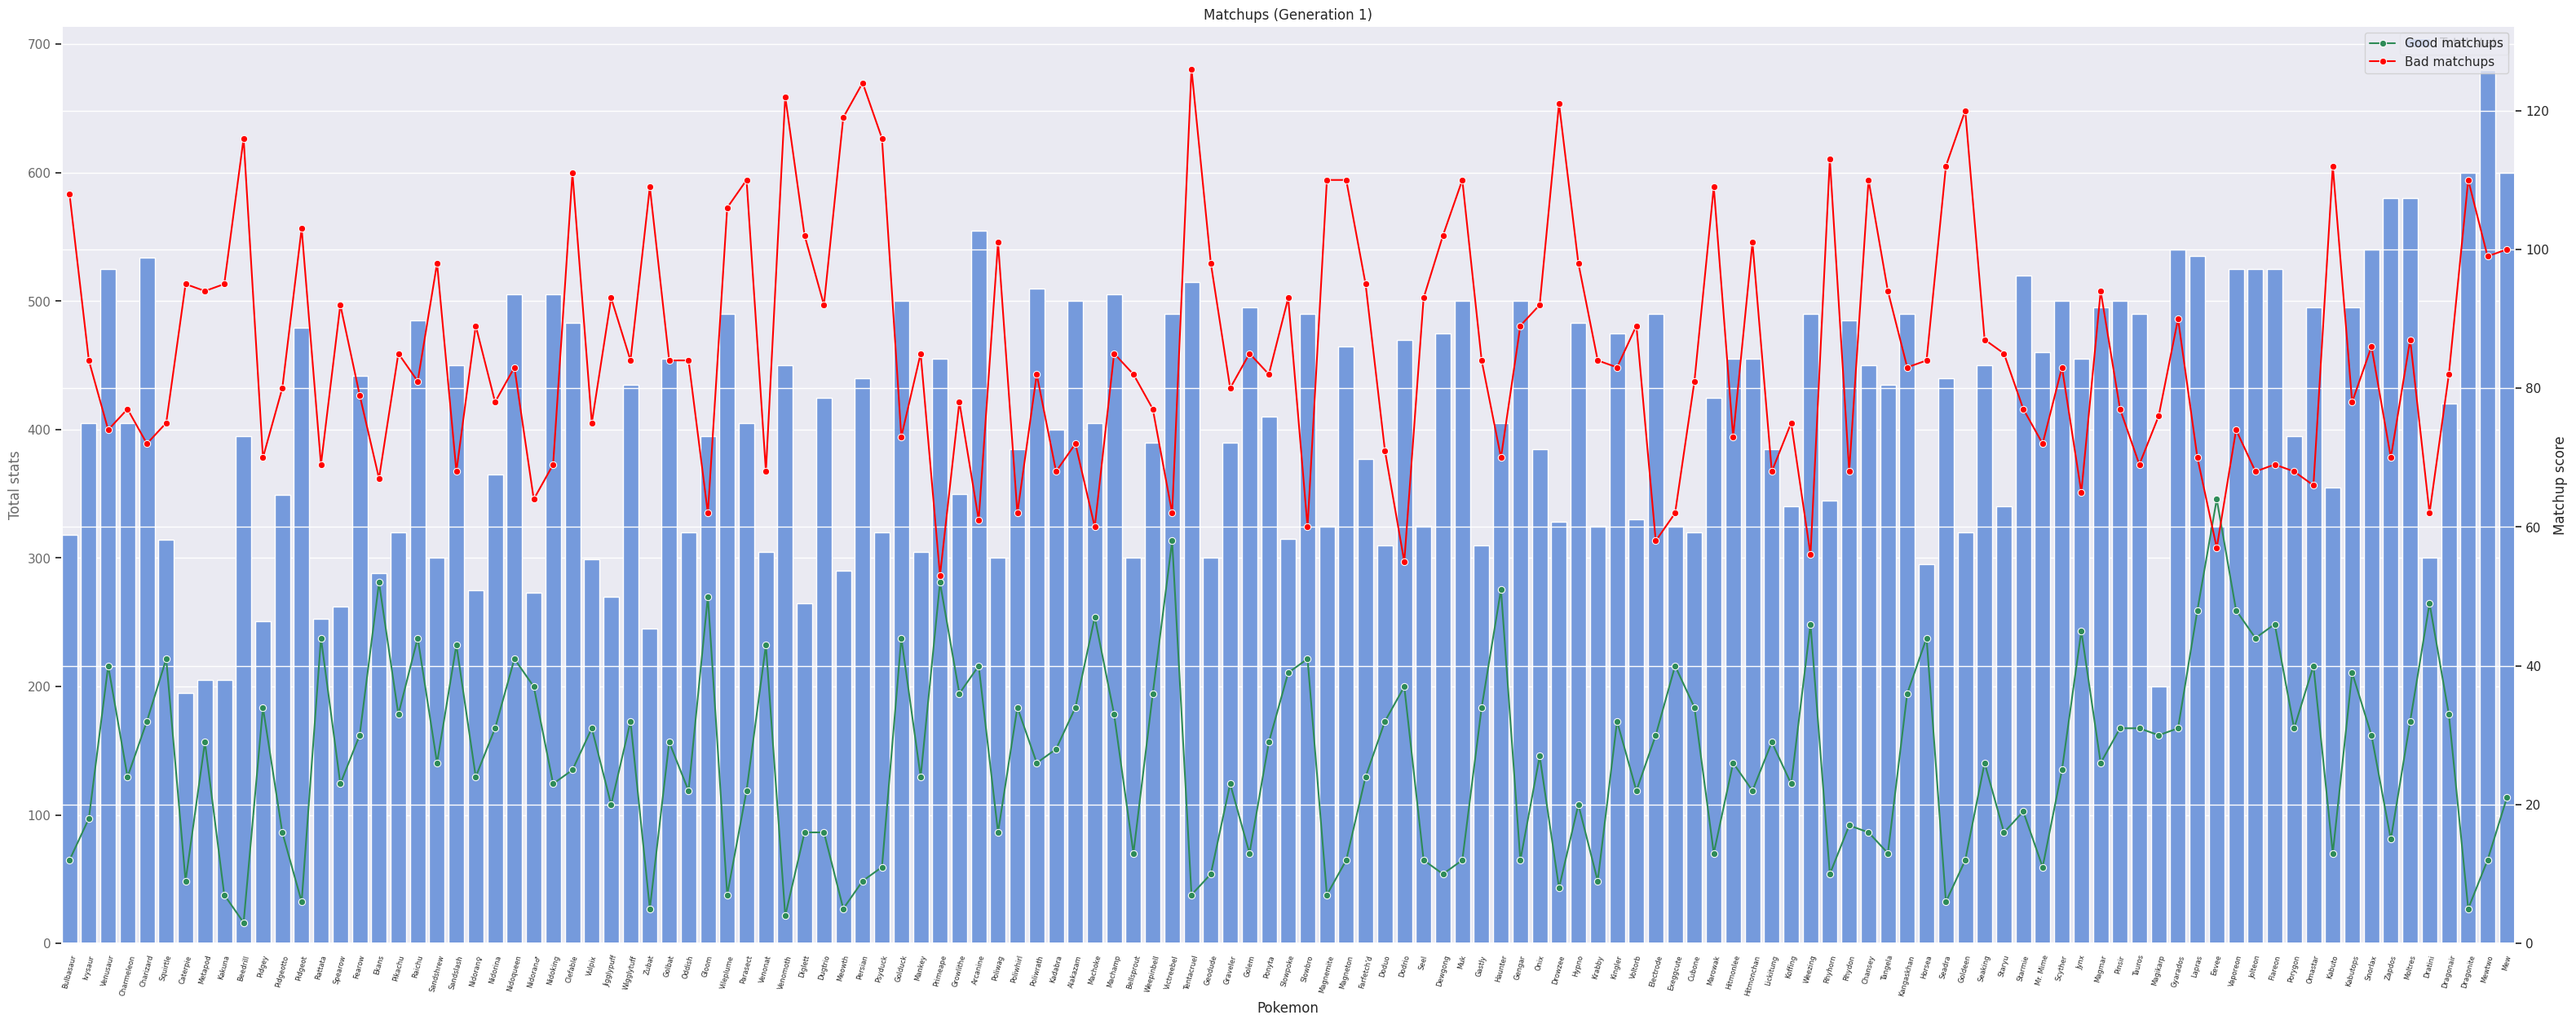

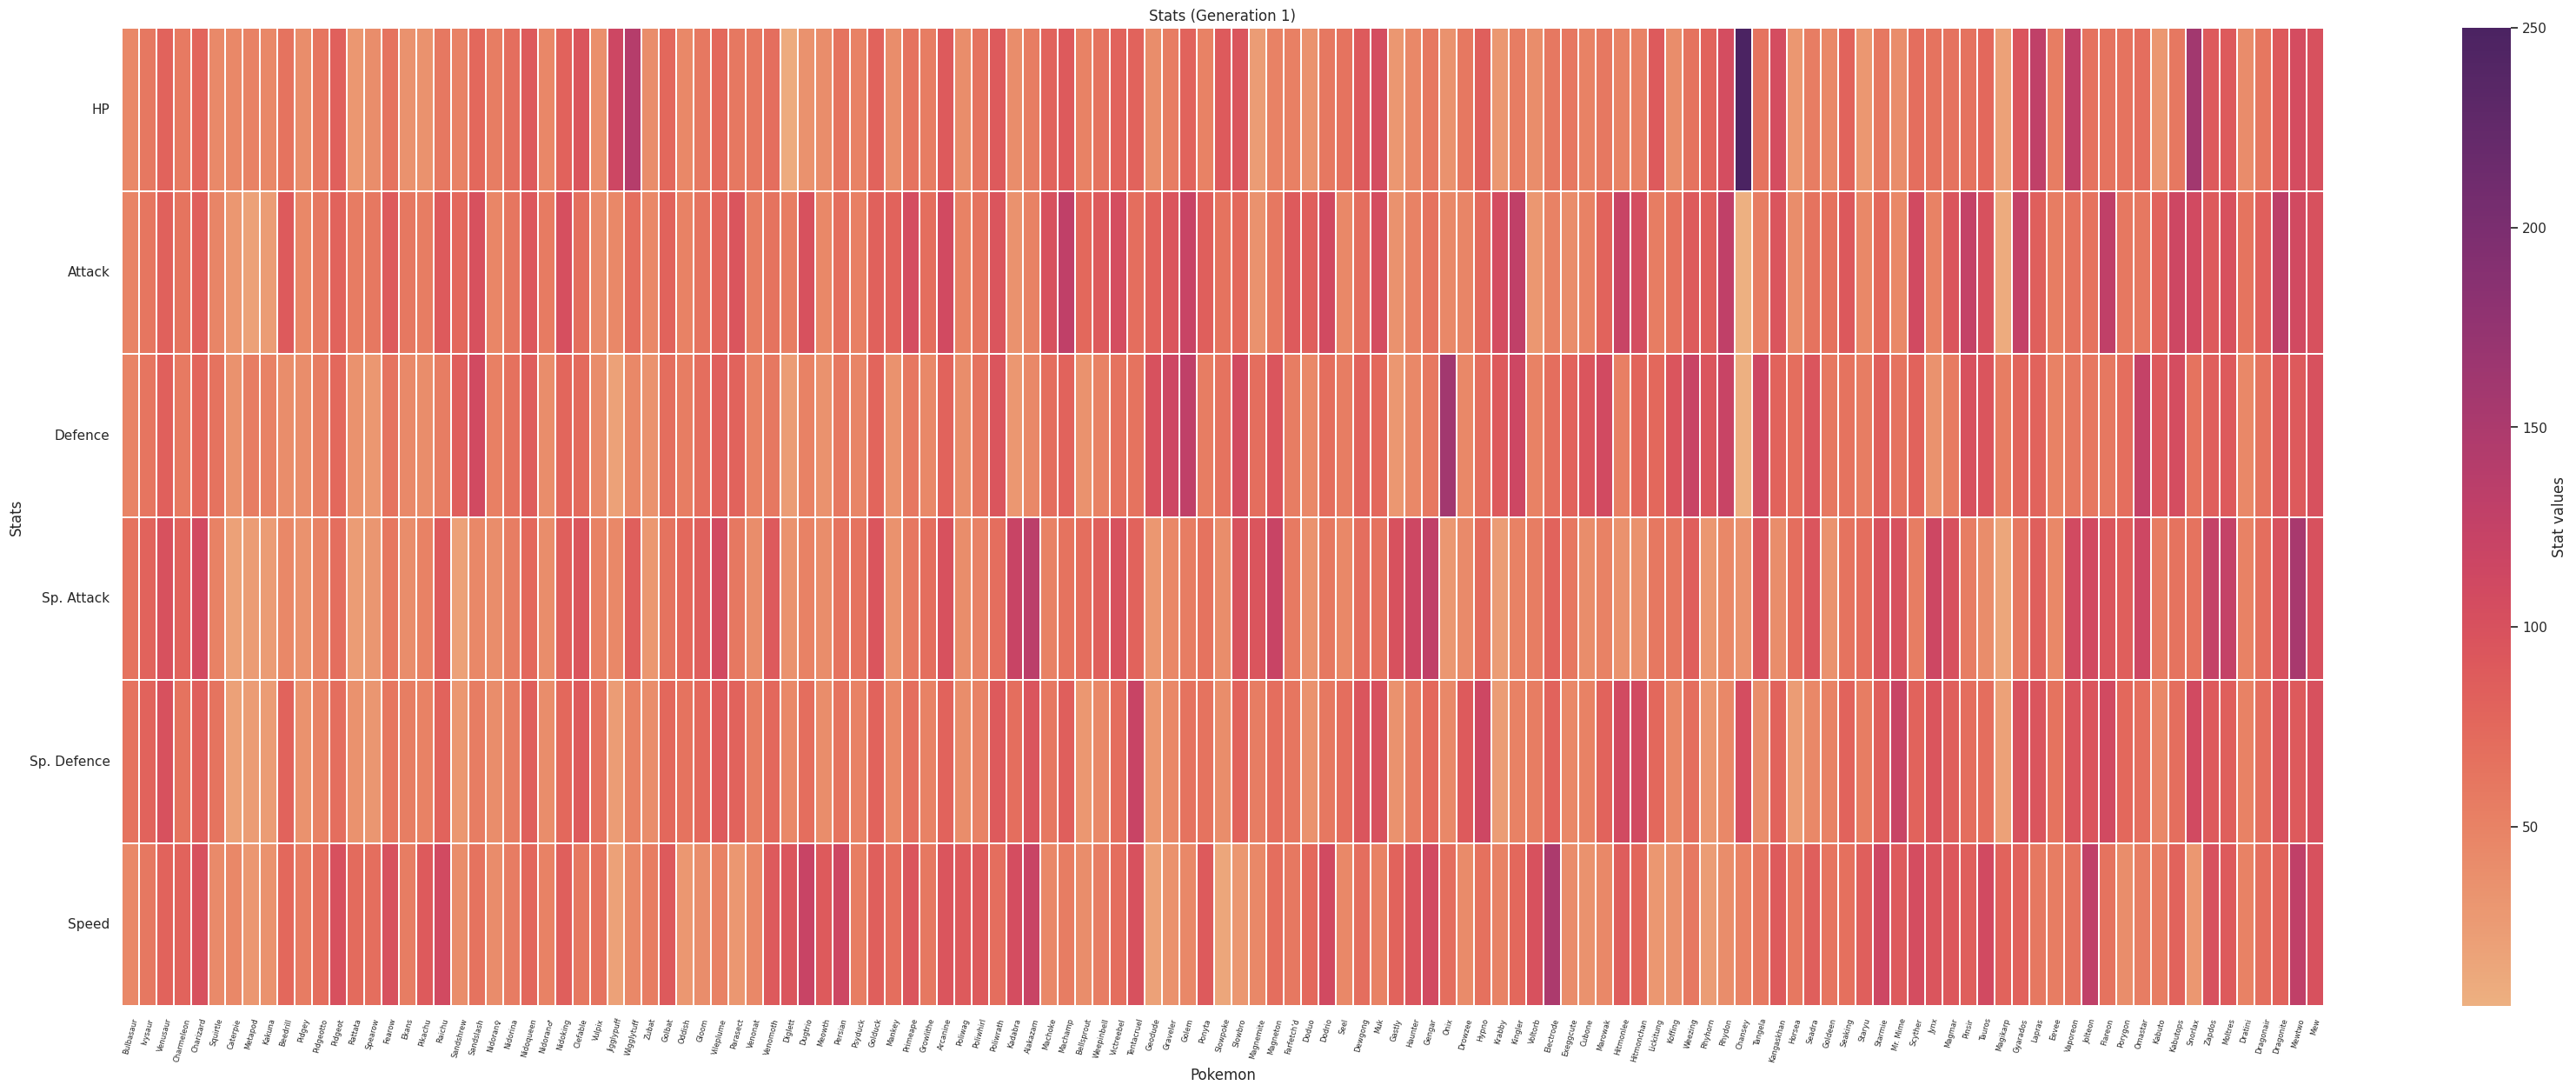

In [ ]:

# Program #

data_arr = {
    "_index": {}
}
plot_data = {}

# Validation

if config_min_gen > config_max_gen:
    print("config_max_gen needs to be smaller or equal than config_min_gen")
    exit()

if config_min_gen < 1 or config_min_gen > 8:
    print("config_min_gen needs to be a number from 1 to 8")
    exit()

if config_max_gen < 1 or config_max_gen > 8:
    print("config_max_gen needs to be a number from 1 to 8")
    exit()

# CSV Reading

def get_csv_row(row):
    if len(row) < 3:
        return

    if row[0] in data_arr["_index"]:
        gen_id_0 = "gen_"+data_arr["_index"][row[0]]
        if (row[0] == row[2]):
            data_arr[gen_id_0][row[0]]["good_matchup"].append(row[1])
        else:
            data_arr[gen_id_0][row[0]]["bad_matchup"].append(row[1])
    if row[1] in data_arr["_index"]:
        gen_id_1 = "gen_"+data_arr["_index"][row[1]]
        if (row[1] == row[2]):
            data_arr[gen_id_1][row[1]]["bad_matchup"].append(row[0])
        else:
            data_arr[gen_id_1][row[1]]["bad_matchup"].append(row[0])


def get_csv_data():
    data_frame_mons = pd.read_csv(config_combat_csv, header=None)
    for row in data_frame_mons.itertuples(index=False, name=None):
        get_csv_row(row)


# Scrapping

def get_stats_from_gen(gen_num):
    request = urllib.request.build_opener()
    request.addheaders = [('User-Agent', 'v1')]
    urllib.request.install_opener(request)
    response = urllib.request.urlopen(config_stats_url + gen_num)

    raw_html = response.read().decode("utf-8")
    soup = BeautifulSoup(raw_html, "html.parser")

    dex_table = soup.find("table", id="pokedex")

    mon_rows = dex_table.find_all(['tr'])
    for row in mon_rows:
        td_items = row.find_all(['td'])
        if (len(td_items) < 10 or not td_items[0].has_attr("data-sort-value")):
            continue

        if not "gen_"+gen_num in data_arr:
            data_arr["gen_"+gen_num] = {}

        if td_items[1].find("small"):
            continue

        data_arr["_index"][td_items[0].get("data-sort-value")] = gen_num
        data_arr["gen_"+gen_num][td_items[0].get("data-sort-value")] = {
            "name": td_items[1].get_text(),
            "types": [i.get_text() for i in td_items[2].find_all('a')],
            "stats_total": td_items[3].get_text(),
            "stats_hp": td_items[4].get_text(),
            "stats_attack": td_items[5].get_text(),
            "stats_defence": td_items[6].get_text(),
            "stats_sp_attack": td_items[7].get_text(),
            "stats_sp_defence": td_items[8].get_text(),
            "stats_speed": td_items[9].get_text(),
            "good_matchup": [],
            "bad_matchup": [],
        }


def get_stats_data():
    for i in range(1, config_max_gen + 1):
        print("Gen " + str(i))
        get_stats_from_gen(str(i))
        time.sleep(1)

def cleanup_data():
    for gen in list(data_arr.keys()):
        if gen == "_index":
            continue

        plot_data[gen] = {
            "name": [],
            "good_matchups": [],
            "bad_matchups": [],
            "stats_total": [],
            "stats_hp": [],
            "stats_attack": [],
            "stats_defence": [],
            "stats_sp_attack": [],
            "stats_sp_defence": [],
            "stats_speed": [],
        }

        for pokemom in list(data_arr[gen].values()):
            if pokemom["good_matchup"] and pokemom["bad_matchup"]:
                plot_data[gen]["name"].append(pokemom["name"])
                plot_data[gen]["good_matchups"].append(len(pokemom["good_matchup"]))
                plot_data[gen]["bad_matchups"].append(len(pokemom["bad_matchup"]))
                plot_data[gen]["stats_total"].append(int(pokemom["stats_total"]))
                plot_data[gen]["stats_hp"].append(int(pokemom["stats_hp"]))
                plot_data[gen]["stats_attack"].append(int(pokemom["stats_attack"]))
                plot_data[gen]["stats_defence"].append(int(pokemom["stats_defence"]))
                plot_data[gen]["stats_sp_attack"].append(int(pokemom["stats_sp_attack"]))
                plot_data[gen]["stats_sp_defence"].append(int(pokemom["stats_sp_defence"]))
                plot_data[gen]["stats_speed"].append(int(pokemom["stats_speed"]))
                """ plot_data[gen]["se_weaknesses"].append(calculate_se_weaknesses(value["types"])) """


def generate_plot():
    for gen, row in plot_data.items():
        dataframe = pd.DataFrame(row)

        # matchups plot

        fig, ax1 = plt.subplots(1, 1, figsize=(32, 15))

        sns.barplot(
            data=dataframe,
            x="name",
            y="stats_total",
            ax=ax1,
            color="cornflowerblue",
            label="Total stats"
        )

        ax1.set_xlabel("Pokemon")
        ax1.set_ylabel("Total stats", color="dimgray")
        ax1.tick_params(axis="y", labelcolor="dimgray")
        ax1.tick_params(axis="x", rotation=75, labelsize=6)
        ax1.set_ylim(bottom=0)

        ax2 = ax1.twinx()

        sns.lineplot(
            data=dataframe,
            x="name",
            y="good_matchups",
            ax=ax2,
            color="SeaGreen",
            marker="o",
            label="Good matchups"
        )

        sns.lineplot(
            data=dataframe,
            x="name",
            y="bad_matchups",
            ax=ax2,
            color="red",
            marker="o",
            label="Bad matchups"
        )

        ax2.set_ylabel("Matchup score")

        ax2.set_ylim(bottom=0)
        ax1.margins(x=0)
        ax2.margins(x=0)

        fig.subplots_adjust(left=0.03, right=0.97, top=0.95, bottom=0.2)

        plt.title("Matchups (Generation " + gen.replace("gen_","") + ")")
        plt.show()

        # Heatmap

        stat_columns = [
            "stats_hp",
            "stats_attack",
            "stats_defence",
            "stats_sp_attack",
            "stats_sp_defence",
            "stats_speed"
        ]

        heatmap_data = dataframe.set_index("name")[stat_columns].T
        heatmap_data.index = [
            "HP",
            "Attack",
            "Defence",
            "Sp. Attack",
            "Sp. Defence",
            "Speed"
        ]

        fig2, ax3 = plt.subplots(1, 1, figsize=(32, 15))

        sns.heatmap(
            heatmap_data,
            ax=ax3,
            annot=False,
            linewidths=0.2,
            cbar_kws={"label": "Stat values"},
            square=False,
            cmap="flare",
            xticklabels=1
        )

        fig2.subplots_adjust(left=0.06, right=1.05, top=0.95, bottom=0.2)
        ax3.set_aspect("auto")
        ax3.set_xlabel("Pokemon")
        ax3.set_ylabel("Stats")
        ax3.tick_params(axis="x", rotation=75, labelsize=6)
        ax3.tick_params(axis="y", rotation=0)

        plt.title("Stats (Generation " + gen.replace("gen_","") + ")")
        plt.show()


get_stats_data()
get_csv_data()
cleanup_data()
generate_plot()